<a href="https://colab.research.google.com/github/srihari4420/DBsqlite_Generation_Assignment-24065408-/blob/main/H1N1_vaccine_allocation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# H1N1 vaccine allocation: Dataset B

The town must decide, person by person, whether to post an H1N1 vaccine to their home. The aim is to keep the town's total spend as low as possible, where spend is vaccine costs plus hospitalisation costs.

**Contents**

1. The problem and the decision rule
2. Data exploration
3. Preprocessing
4. Modelling vaccine acceptance
5. Hospitalisation risk
6. Performance analysis (cost)
7. Submission
8. Conclusions and limitations

## 1. The problem and the decision rule

The brief sets these rules:

* Everyone is infected (100% infection rate at the winter parties).
* A vaccine costs **\$500**. A hospitalisation costs **\$25,000**.
* A posted vaccine that the person refuses is wasted, but still paid for.
* Anyone who wants a vaccine and doesn't receive one must be paid \$500 by the town.

For each person, write

* $q$ = probability they accept the vaccine (predicted from the survey),
* $p$ = probability they are hospitalised if unvaccinated,
* $VE$ = how much the vaccine reduces that risk.

The expected cost of each choice is

$$\text{Send:}\quad C_v + p\,C_h\,(1 - q\,VE)$$
$$\text{Don't send:}\quad q\,C_v + p\,C_h$$

Sending is cheaper when

$$q \;>\; \frac{C_v}{C_v + VE \cdot p \cdot C_h}$$

So the task splits into two parts. The first is a classifier for $q$ that gives **well-calibrated probabilities**, because the rule uses the probability's actual value, not just how people are ranked. The second is an estimate of $p$ and $VE$ from outside the dataset, as the brief suggests.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, brier_score_loss, log_loss,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold,
                                     cross_val_predict, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

RANDOM_STATE = 42
TARGET, ID_COL = "h1n1_vaccine", "respondent_id"
VACCINE_COST, HOSP_COST = 500, 25_000

TRAIN_PATH = "/content/dataset_B_training (1).csv"
TEST_PATH = "/content/dataset_B_testing.csv"
EXAMPLE_SUB_PATH = "/content/dataset_B_example_submission.csv"

# Chart styling: light surface, recessive axes, one fixed categorical order
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # blue, orange, aqua, yellow
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8, "axes.axisbelow": True, "lines.linewidth": 2,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.dpi": 110,
})

## 2. Data exploration

### 2.1 First look

In [7]:
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
example_sub = pd.read_csv(EXAMPLE_SUB_PATH)

print(f"Training: {train.shape[0]:,} rows x {train.shape[1]} columns")
print(f"Testing:  {test.shape[0]:,} rows x {test.shape[1]} columns")
print(f"Test IDs match the example submission, in order: "
      f"{list(test[ID_COL]) == list(example_sub[ID_COL])}")
print(f"Duplicate IDs in training: {train[ID_COL].duplicated().sum()}")
train.head()

Training: 4,756 rows x 31 columns
Testing:  4,749 rows x 30 columns
Test IDs match the example submission, in order: True
Duplicate IDs in training: 0


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,doctor_recc_h1n1,child_under_6_months,health_worker,health_insurance,opinion_h1n1_vacc_effective,opinion_h1n1_risk,opinion_h1n1_sick_from_vacc,age_group,education,race,sex,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,h1n1_vaccine
0,1,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,4.0,4.0,1.0,45 - 54 Years,Some College,White,Female,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",2.0,1.0,science,0,0
1,2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,3.0,1.0,2.0,18 - 34 Years,Some College,White,Female,Below Poverty,Not Married,Own,Employed,Non-MSA,0.0,3.0,wholesale,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,NaN,0.0,0.0,1.0,3.0,4.0,2.0,45 - 54 Years,College Graduate,White,Female,"> $75,000",Not Married,Own,Employed,"MSA, Principle City",0.0,0.0,education,0,1
3,4,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,2.0,1.0,4.0,18 - 34 Years,College Graduate,White,Female,"<= $75,000, Above Poverty",Not Married,Rent,Not in Labor Force,Non-MSA,0.0,0.0,NaN,0,0
4,5,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,2.0,2.0,1.0,18 - 34 Years,< 12 Years,White,Female,NaN,Not Married,NaN,Unemployed,Non-MSA,3.0,0.0,NaN,0,0


In [8]:
FEATURES = [c for c in train.columns if c not in (ID_COL, TARGET)]
assert set(FEATURES) == set(test.columns) - {ID_COL}, "Train and test columns differ"

summary = pd.DataFrame({
    "dtype": train[FEATURES].dtypes.astype(str),
    "unique values": train[FEATURES].nunique(),
    "missing % (train)": (train[FEATURES].isna().mean() * 100).round(1),
    "missing % (test)": (test[FEATURES].isna().mean() * 100).round(1),
}).sort_values("missing % (train)", ascending=False)
summary

,dtype,unique values,missing % (train),missing % (test)
employment_sector,object,21,49.7,50.6
health_insurance,float64,2,40.5,41.7
income_poverty,object,3,15.0,16.8
doctor_recc_h1n1,float64,2,6.7,7.3
rent_or_own,object,2,6.6,8.0
employment_status,object,3,4.9,5.8
marital_status,object,2,4.8,5.7
education,object,4,4.7,5.7
health_worker,float64,2,2.8,3.1
child_under_6_months,float64,2,2.8,3.3


### 2.2 Missing values

Two columns stand out. About half of `employment_sector` is missing, because it is only answered by people in work. About 40% of `health_insurance` is missing. The test set shows the same pattern, so missingness is part of the data rather than a fault in one file. That matters for preprocessing: for these columns, *not answering* may itself carry information.

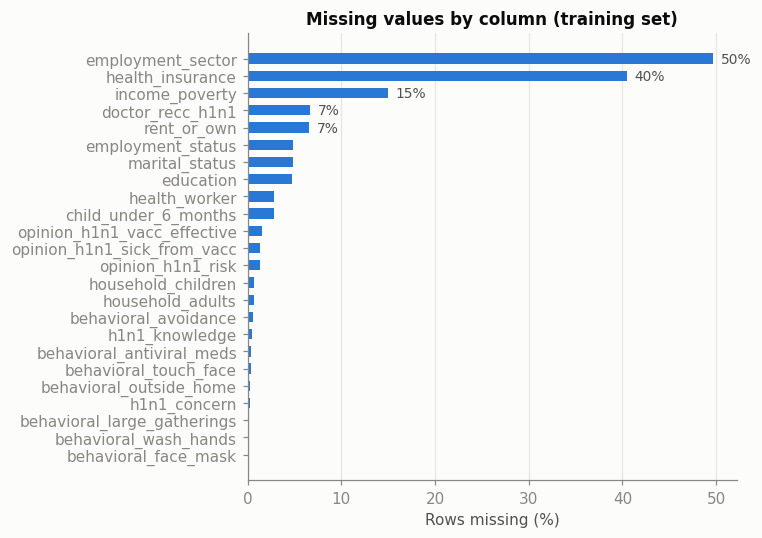

In [9]:
miss = summary[summary["missing % (train)"] > 0]["missing % (train)"].sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(miss.index, miss.values, color=SERIES[0], height=0.6)
for y, v in enumerate(miss.values):
    if v >= 5:
        ax.text(v + 0.8, y, f"{v:.0f}%", va="center", color=INK_2, fontsize=9)
ax.set_xlabel("Rows missing (%)")
ax.set_title("Missing values by column (training set)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### 2.3 The target

In [10]:
counts = train[TARGET].value_counts().sort_index()
print(counts.rename({0: "Did not take vaccine", 1: "Took vaccine"}).to_string())
print(f"\nAcceptance rate: {train[TARGET].mean():.1%}")

h1n1_vaccine
Did not take vaccine    2882
Took vaccine            1874

Acceptance rate: 39.4%


About 39% of respondents took the vaccine. The classes are imbalanced but not severely, so no resampling is needed. Resampling would also distort the predicted probabilities, which the decision rule depends on.

### 2.4 What goes with acceptance?

The charts show the acceptance rate within each group for the features most likely to matter. The grey number above each bar is the group size.

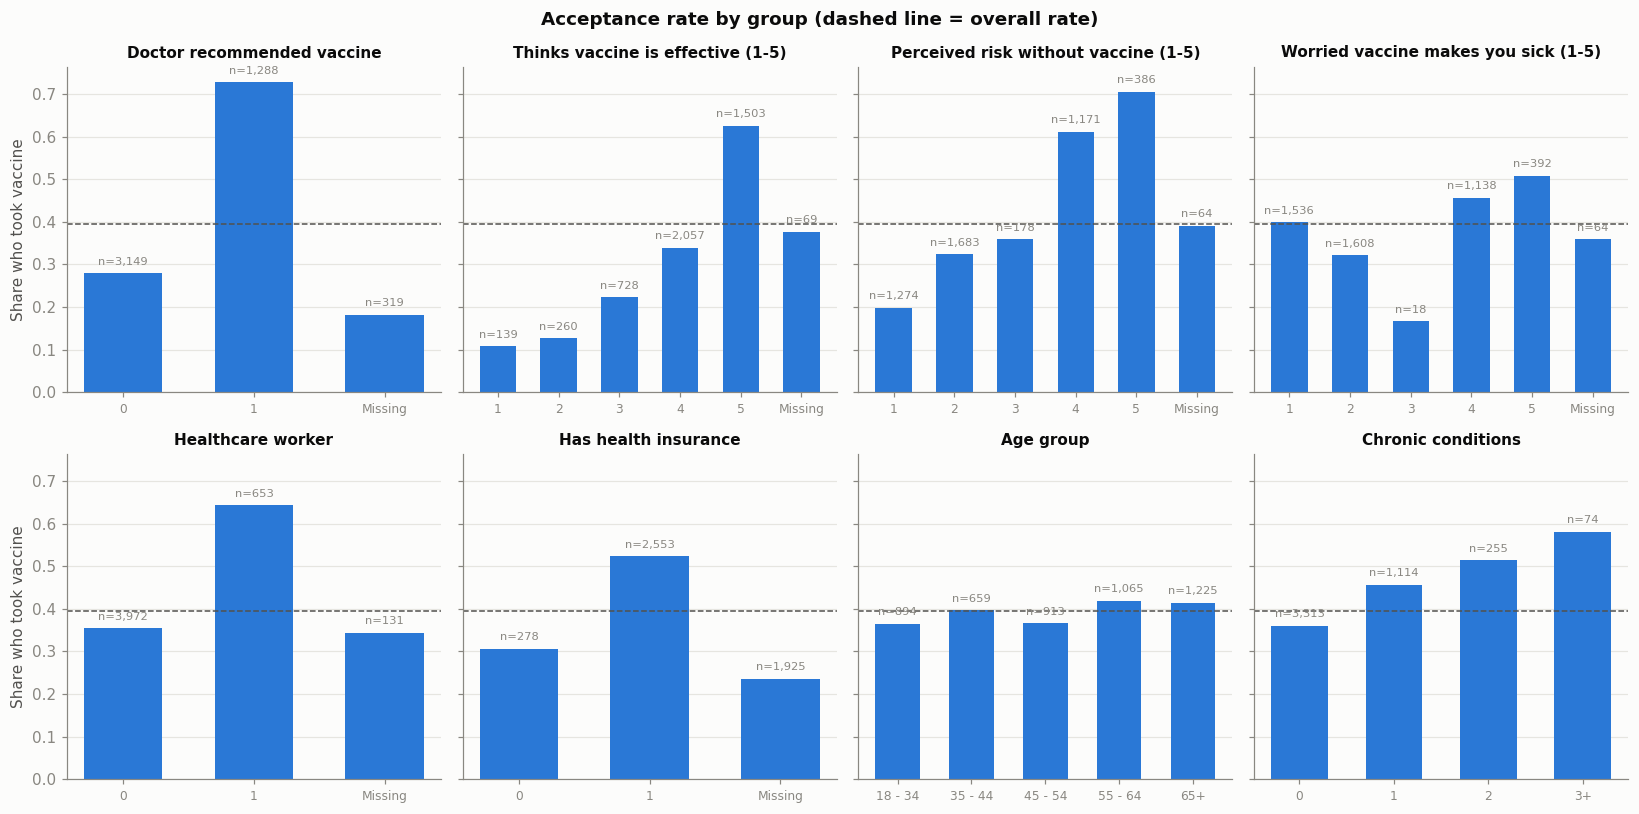

In [11]:
explore = [
    ("doctor_recc_h1n1", "Doctor recommended vaccine"),
    ("opinion_h1n1_vacc_effective", "Thinks vaccine is effective (1-5)"),
    ("opinion_h1n1_risk", "Perceived risk without vaccine (1-5)"),
    ("opinion_h1n1_sick_from_vacc", "Worried vaccine makes you sick (1-5)"),
    ("health_worker", "Healthcare worker"),
    ("health_insurance", "Has health insurance"),
    ("age_group", "Age group"),
    ("number_chronic_med_conditions", "Chronic conditions"),
]
overall = train[TARGET].mean()

fig, axes = plt.subplots(2, 4, figsize=(15, 7.5), sharey=True)
for ax, (col, title) in zip(axes.ravel(), explore):
    s = train[col]
    if col == "number_chronic_med_conditions":
        s = s.clip(upper=3).astype(int).astype(str).replace({"3": "3+"})
    elif col == "age_group":
        s = s.str.replace(" Years", "")
    elif pd.api.types.is_numeric_dtype(s):
        s = s.astype("Int64").astype(str).replace({"<NA>": "Missing"})
    s = s.fillna("Missing")
    g = train.groupby(s)[TARGET].agg(["mean", "size"])
    ax.bar(g.index.astype(str), g["mean"], color=SERIES[0], width=0.6)
    for x, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(x, m + 0.02, f"n={n:,}", ha="center", fontsize=7.5, color=MUTED)
    ax.axhline(overall, color=INK_2, lw=1, ls="--")
    ax.set_title(title, fontsize=10)
    ax.tick_params(axis="x", labelsize=8, rotation=0)
    ax.grid(axis="x", visible=False)
for ax in axes[:, 0]:
    ax.set_ylabel("Share who took vaccine")
fig.suptitle("Acceptance rate by group (dashed line = overall rate)", fontweight="bold")
plt.tight_layout()
plt.show()

In [12]:
# How strongly each numeric feature moves with acceptance (point-biserial correlation)
num_cols = train[FEATURES].select_dtypes("number").columns
corr = (train[num_cols].corrwith(train[TARGET])
        .rename("correlation with acceptance").sort_values(key=abs, ascending=False))
corr.round(3).to_frame()

,correlation with acceptance
doctor_recc_h1n1,0.414
opinion_h1n1_risk,0.362
opinion_h1n1_vacc_effective,0.325
health_worker,0.205
h1n1_knowledge,0.149
h1n1_concern,0.143
health_insurance,0.129
number_chronic_med_conditions,0.111
behavioral_touch_face,0.103
behavioral_wash_hands,0.093


**What the exploration shows**

* **A doctor's recommendation is the strongest single signal.** About 73% of people whose doctor recommended the vaccine took it, against 28% of those whose doctor didn't.
* **Opinions matter a lot.** Acceptance climbs steadily with belief that the vaccine works and with perceived personal risk.
* **Worry about side effects does not behave as expected.** People who were *more* worried were slightly *more* likely to accept. A likely reason is that worry goes with general engagement in the topic. It is a reminder not to assume a direction before looking.
* **Healthcare workers and insured people accept more often.** People who left `health_insurance` blank accept *less* often than either the "yes" or the "no" group, which supports treating missing as its own category.
* **Chronic conditions raise acceptance; age makes little difference.** Chronic conditions matter even more for hospitalisation risk (section 5).
* The behaviour columns (masks, hand washing and so on) are only weakly linked to acceptance.

### 2.5 Are the training and test sets alike?

If the test set came from a different population, a model tuned on training data could mislead. The table compares the share of each category, and the mean of each numeric column, across the two files.

In [13]:
rows = []
for c in FEATURES:
    if pd.api.types.is_numeric_dtype(train[c]):
        a, b = train[c].mean(), test[c].mean()
        rows.append((c, "mean", round(a, 3), round(b, 3), round(abs(a - b) / (train[c].std() or 1), 3)))
    else:
        pa = train[c].fillna("Missing").value_counts(normalize=True)
        pb = test[c].fillna("Missing").value_counts(normalize=True)
        diff = pa.subtract(pb, fill_value=0).abs()
        rows.append((c, f"largest category gap ({diff.idxmax()})",
                     round(pa.get(diff.idxmax(), 0), 3), round(pb.get(diff.idxmax(), 0), 3),
                     round(diff.max(), 3)))
shift = pd.DataFrame(rows, columns=["feature", "measure", "train", "test", "gap"])
shift.sort_values("gap", ascending=False).head(10)

,feature,measure,train,test,gap
1,h1n1_knowledge,mean,1.307,1.282,0.041
14,opinion_h1n1_risk,mean,2.512,2.563,0.038
0,h1n1_concern,mean,1.659,1.691,0.036
11,health_worker,mean,0.141,0.130,0.032
8,behavioral_touch_face,mean,0.705,0.690,0.032
20,income_poverty,"largest category gap (> $75,000)",0.282,0.255,0.027
28,number_chronic_med_conditions,mean,0.391,0.374,0.025
3,behavioral_avoidance,mean,0.741,0.731,0.024
2,behavioral_antiviral_meds,mean,0.057,0.053,0.021
19,sex,largest category gap (Female),0.614,0.594,0.020


The gaps are all small: under a tenth of a standard deviation for numeric columns, and a couple of percentage points for categories. The test set looks like it was drawn from the same population, so cross-validated results on the training set should be a fair guide to test performance.

### 2.6 Chronic conditions (needed for hospitalisation risk)

In [14]:
chronic = pd.concat({
    "train": train["number_chronic_med_conditions"].clip(upper=3).value_counts(normalize=True),
    "test": test["number_chronic_med_conditions"].clip(upper=3).value_counts(normalize=True),
}, axis=1).sort_index().rename(index={3: "3+"})
(chronic * 100).round(1).rename_axis("chronic conditions").astype(str) + "%"

,train,test
chronic conditions,,
0,69.7%,71.0%
1,23.4%,22.4%
2,5.4%,5.2%
3+,1.6%,1.4%


## 3. Preprocessing

The columns fall into four groups, and each is handled differently:

| Group | Columns | Treatment |
|---|---|---|
| Binary (0/1) | behavioural questions, `doctor_recc_h1n1`, `child_under_6_months`, `health_worker`, `health_insurance` | kept as numbers |
| Ordered scales and counts | concern, knowledge, the three opinion scales, household sizes, chronic conditions | kept as numbers |
| Ordered categories | `age_group`, `education`, `income_poverty` | mapped to 0, 1, 2, ... in their natural order |
| Unordered categories | `race`, `sex`, `marital_status`, `rent_or_own`, `employment_status`, `census_msa`, `employment_sector` | one-hot (linear model) or native categorical splits (trees) |

**Missing values.** Two approaches, one per model family:

* *Gradient boosting* handles missing values natively. At each split it learns which side missing values should go, so a blank `health_insurance` can behave differently from 0 or 1. Missing categories become their own level, `"Missing"`.
* *Logistic regression and random forest* need complete inputs. Numbers get median imputation **plus an indicator column** marking where a value was filled in. Categories get the `"Missing"` level before one-hot encoding.

The three opinion scales use 3 for "Don't know", which sits in the middle of the scale. That is a fair approximation and is left as it is.

All imputation, scaling and encoding sits inside scikit-learn pipelines. It is therefore re-fitted on the training part of every cross-validation fold, so nothing leaks from validation rows into training.

In [15]:
ORDINAL_MAPS = {
    "age_group": ["18 - 34 Years", "35 - 44 Years", "45 - 54 Years", "55 - 64 Years", "65+ Years"],
    "education": ["< 12 Years", "12 Years", "Some College", "College Graduate"],
    "income_poverty": ["Below Poverty", "<= $75,000, Above Poverty", "> $75,000"],
}
NOMINAL = ["race", "sex", "marital_status", "rent_or_own",
           "employment_status", "census_msa", "employment_sector"]
NUMERIC = [c for c in FEATURES if c not in NOMINAL and c not in ORDINAL_MAPS]


def prepare(df):
    # Shared, stateless step: ordered categories to numbers, blank categories to 'Missing'
    out = df[FEATURES].copy()
    for col, order in ORDINAL_MAPS.items():
        out[col] = out[col].map({v: i for i, v in enumerate(order)}).astype(float)
    for col in NOMINAL:
        out[col] = out[col].fillna("Missing").astype(str)
    return out


X = prepare(train)
y = train[TARGET].to_numpy()
X_test = prepare(test)
NUM_ALL = NUMERIC + list(ORDINAL_MAPS)

unseen = {c: sorted(set(X_test[c]) - set(X[c])) for c in NOMINAL}
print("Categories in test but not in training:", {k: v for k, v in unseen.items() if v} or "none")
print(f"{len(NUM_ALL)} numeric/ordinal features, {len(NOMINAL)} nominal features")

Categories in test but not in training: none
22 numeric/ordinal features, 7 nominal features


In [16]:
# Logistic regression: impute + missing flags, scale, one-hot
linear_prep = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                      ("scale", StandardScaler())]), NUM_ALL),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), NOMINAL),
])

# Random forest: same imputation, no scaling needed
forest_prep = ColumnTransformer([
    ("num", SimpleImputer(strategy="median", add_indicator=True), NUM_ALL),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), NOMINAL),
])

# Gradient boosting: leave NaN in numbers, integer-code the nominal columns
boost_prep = ColumnTransformer([
    ("num", "passthrough", NUM_ALL),
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan), NOMINAL),
])
BOOST_CAT_MASK = [False] * len(NUM_ALL) + [True] * len(NOMINAL)

print("Logistic regression input width:", linear_prep.fit_transform(X).shape[1])
print("Gradient boosting input width:   ", boost_prep.fit_transform(X).shape[1])

Logistic regression input width: 81
Gradient boosting input width:    29


## 4. Modelling vaccine acceptance

Three model families are compared, from simple to flexible:

1. **Logistic regression**: a transparent baseline that is often well calibrated.
2. **Random forest**: non-linear, but its probabilities tend to bunch away from 0 and 1.
3. **Gradient boosting** (`HistGradientBoostingClassifier`): usually the strongest on tabular survey data like this.

Each is scored with 5-fold stratified cross-validation. The predictions used for scoring are *out-of-fold*: each person's probability comes from a model that never saw them. Log loss is the main metric because it rewards honest probabilities. ROC AUC (ranking quality) and Brier score are reported alongside it.

### 4.1 Tuning

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def boost_pipeline(**params):
    return Pipeline([("prep", boost_prep), ("model", HistGradientBoostingClassifier(
        categorical_features=BOOST_CAT_MASK, random_state=RANDOM_STATE, **params))])

boost_grid = GridSearchCV(
    boost_pipeline(),
    {"model__learning_rate": [0.03, 0.06],
     "model__max_leaf_nodes": [8, 15, 31],
     "model__max_iter": [300],
     "model__l2_regularization": [1.0],
     "model__early_stopping": [True],
     "model__validation_fraction": [0.15],
     "model__n_iter_no_change": [30]},
    scoring="neg_log_loss", cv=cv, n_jobs=-1,
).fit(X, y)
print("Best gradient boosting settings:",
      {k.replace("model__", ""): v for k, v in boost_grid.best_params_.items()
       if k.split("__")[1] in ("learning_rate", "max_leaf_nodes")})

lr_grid = GridSearchCV(
    Pipeline([("prep", linear_prep), ("model", LogisticRegression(max_iter=2000))]),
    {"model__C": [0.03, 0.1, 0.3, 1.0]}, scoring="neg_log_loss", cv=cv, n_jobs=-1,
).fit(X, y)
print("Best logistic regression C:", lr_grid.best_params_["model__C"])

Best gradient boosting settings: {'learning_rate': 0.03, 'max_leaf_nodes': 8}
Best logistic regression C: 0.1


### 4.2 Comparison

In [19]:
best_boost_params = {k.replace("model__", ""): v for k, v in boost_grid.best_params_.items()}

candidates = {
    "Logistic regression": lr_grid.best_estimator_,
    "Random forest": Pipeline([("prep", forest_prep), ("model", RandomForestClassifier(
        n_estimators=500, min_samples_leaf=5, max_features="sqrt",
        n_jobs=-1, random_state=RANDOM_STATE))]),
    "Gradient boosting": boost_pipeline(**best_boost_params),
    "Gradient boosting + calibration": CalibratedClassifierCV(
        boost_pipeline(**best_boost_params), method="isotonic", cv=5),
}

oof = {}
for name, model in candidates.items():
    oof[name] = cross_val_predict(model, X, y, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

scores = pd.DataFrame({
    name: {"Log loss": log_loss(y, q), "Brier score": brier_score_loss(y, q),
           "ROC AUC": roc_auc_score(y, q), "Accuracy (0.5 cut-off)": accuracy_score(y, q >= 0.5)}
    for name, q in oof.items()
}).T.round(4)
scores.sort_values("Log loss")

,Log loss,Brier score,ROC AUC,Accuracy (0.5 cut-off)
Gradient boosting + calibration,0.4582,0.1477,0.8534,0.7878
Gradient boosting,0.4607,0.1489,0.8511,0.7862
Logistic regression,0.4646,0.1500,0.8494,0.7885
Random forest,0.4785,0.1541,0.8525,0.7836


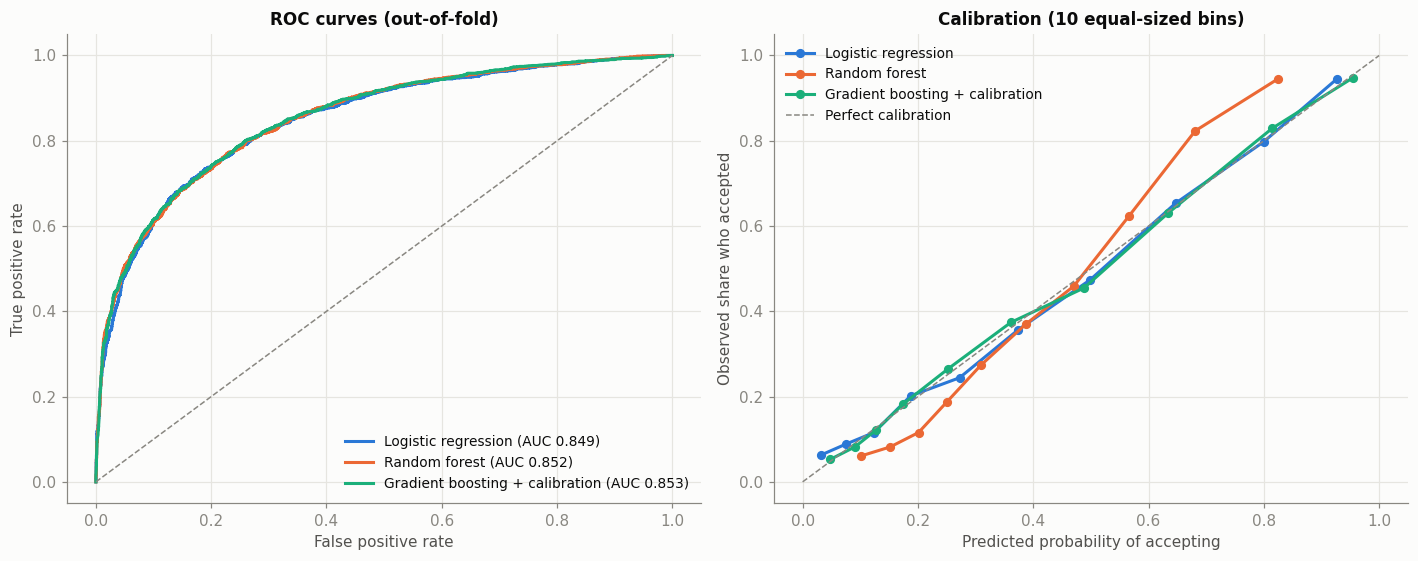

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2))
show = ["Logistic regression", "Random forest", "Gradient boosting + calibration"]

for name, colour in zip(show, SERIES):
    fpr, tpr, _ = roc_curve(y, oof[name])
    ax1.plot(fpr, tpr, color=colour, label=f"{name} (AUC {roc_auc_score(y, oof[name]):.3f})")
ax1.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--")
ax1.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves (out-of-fold)")
ax1.legend(loc="lower right", fontsize=9)

for name, colour in zip(show, SERIES):
    frac, mean_pred = calibration_curve(y, oof[name], n_bins=10, strategy="quantile")
    ax2.plot(mean_pred, frac, marker="o", ms=5, color=colour, label=name)
ax2.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--", label="Perfect calibration")
ax2.set(xlabel="Predicted probability of accepting", ylabel="Observed share who accepted",
        title="Calibration (10 equal-sized bins)")
ax2.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

In [21]:
CHOSEN = scores["Log loss"].idxmin()
q_oof = oof[CHOSEN]
final_model = candidates[CHOSEN]
print(f"Chosen model: {CHOSEN}")
print(f"  log loss {scores.loc[CHOSEN, 'Log loss']:.4f}, ROC AUC {scores.loc[CHOSEN, 'ROC AUC']:.4f}")

bins = pd.cut(q_oof, [0, .1, .2, .3, .5, .7, .85, .95, 1], include_lowest=True)
pd.DataFrame({"q": q_oof, "y": y}).groupby(bins, observed=True).agg(
    people=("y", "size"), mean_predicted=("q", "mean"), observed_rate=("y", "mean")).round(3)

Chosen model: Gradient boosting + calibration
  log loss 0.4582, ROC AUC 0.8534


,people,mean_predicted,observed_rate
"(-0.001, 0.1]",860,0.065,0.063
"(0.1, 0.2]",998,0.145,0.144
"(0.2, 0.3]",496,0.246,0.260
"(0.3, 0.5]",777,0.394,0.389
"(0.5, 0.7]",625,0.595,0.582
"(0.7, 0.85]",369,0.775,0.780
"(0.85, 0.95]",335,0.904,0.931
"(0.95, 1.0]",296,0.970,0.949


Gradient boosting ranks people best. The model with the lowest log loss is chosen because the decision rule needs **honest probabilities**, and log loss is the metric that measures that directly. The calibration table matters most at the top end. Section 6 shows that most sending decisions happen where the predicted probability is above 0.7, and in those bands predicted and observed acceptance agree closely.

### 4.3 Which features drive acceptance?

Permutation importance measures how much worse the log loss gets when one column is shuffled. To keep the measurement honest, it is computed on a 25% hold-out that the model did not train on.

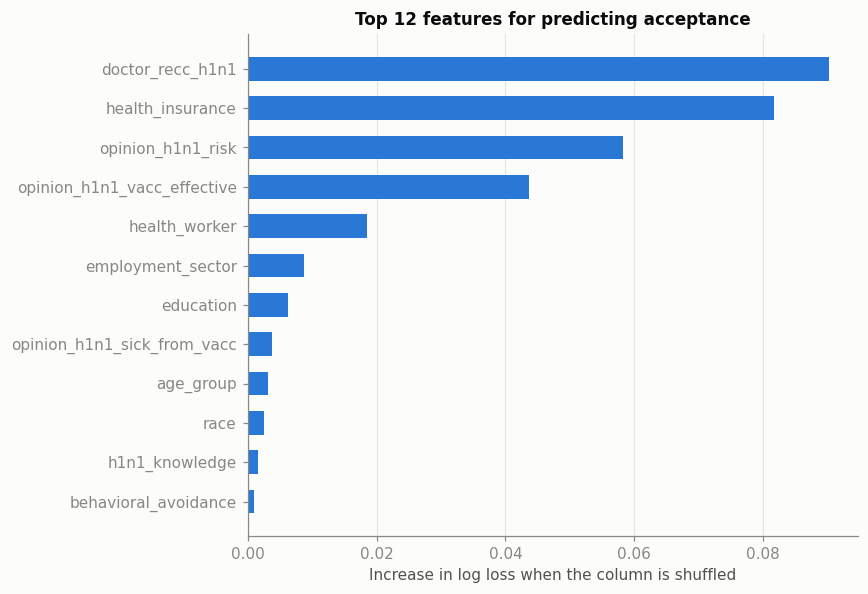

In [22]:
X_fit, X_hold, y_fit, y_hold = train_test_split(X, y, test_size=0.25, stratify=y,
                                                random_state=RANDOM_STATE)
imp_model = boost_pipeline(**best_boost_params).fit(X_fit, y_fit)
imp = permutation_importance(imp_model, X_hold, y_hold, scoring="neg_log_loss",
                             n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
importance = (pd.Series(imp.importances_mean, index=X.columns)
              .sort_values(ascending=False))

top = importance.head(12)[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index, top.values, color=SERIES[0], height=0.6)
ax.set_xlabel("Increase in log loss when the column is shuffled")
ax.set_title("Top 12 features for predicting acceptance")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

The model agrees with the exploration. A doctor's recommendation, health insurance status (including whether the question was answered) and the person's views on risk and effectiveness do most of the work. Demographics add relatively little once those are known.

## 5. Hospitalisation risk

The dataset does not say who ends up in hospital, so $p$ has to come from outside it. The brief encourages generative AI for this step. The figures below were then checked against the published sources they rest on, rather than taken on trust from a single answer.

**Assumptions**

| Quantity | Value used | Basis |
|---|---|---|
| Average hospitalisation risk per infection | **0.45%** (range 0.22%–0.94%) | CDC end-of-pandemic estimates, April 2009 – April 2010: about 274,000 hospitalisations from about 61 million cases. |
| Effect of age | **None (flat)** | Same CDC table: about 160,000 hospitalisations from 35 million cases at ages 18–64, and 27,000 from 6 million at 65+. Both are about 0.45% per case. Older people were *infected* less often in 2009, but here infection is certain. |
| Effect of chronic conditions | relative risk **1 / 5 / 9 / 20** for 0 / 1 / 2 / 3+ conditions | CDC: about 80% of hospitalised adults had an underlying condition. A Sydney case-control study (Ward et al., 2011) found adjusted odds ratios of about 9 for two conditions and 20 for three. |
| Vaccine effectiveness against hospitalisation | **50%** (61% and 72% tested) | US case-control study of non-adjuvanted vaccine: 50%. Meta-analysis (Lansbury et al., 2017): pooled 61%. |

The relative risks are scaled so that the *average* risk across the training population equals 0.45%. As a check, people with at least one condition then account for about three-quarters of expected hospitalisations, close to the CDC's 80%.

Other columns were considered and left out of $p$. `health_worker` and the behaviour questions affect the chance of *catching* flu, which the brief fixes at 100%. Sex and race showed effects in some 2009 studies, but those estimates were not adjusted for infection rates, so they are not used.

In [23]:
AVG_HOSP_RISK = 0.0045
CHRONIC_RR = {0: 1.0, 1: 5.0, 2: 9.0, 3: 20.0}
VE_HOSP = 0.50


def hosp_risk(df, reference=train, avg=AVG_HOSP_RISK, rr=CHRONIC_RR):
    # Risk of hospitalisation if infected and unvaccinated
    rel = lambda d: d["number_chronic_med_conditions"].fillna(0).clip(0, 3).astype(int).map(rr)
    base = avg / rel(reference).mean()
    return (base * rel(df)).clip(upper=1).to_numpy()


def threshold(p, ve=VE_HOSP):
    return VACCINE_COST / (VACCINE_COST + ve * p * HOSP_COST)


p_train = hosp_risk(train)
risk_table = (pd.DataFrame({"chronic conditions": train["number_chronic_med_conditions"].clip(upper=3),
                            "p": p_train})
              .groupby("chronic conditions").agg(people=("p", "size"), hosp_risk=("p", "first")))
risk_table["expected hospital cost if unvaccinated"] = (risk_table["hosp_risk"] * HOSP_COST).round(0)
risk_table["vaccine saves (expected)"] = (risk_table["hosp_risk"] * VE_HOSP * HOSP_COST).round(0)
risk_table["send if P(accept) above"] = threshold(risk_table["hosp_risk"]).round(3)
risk_table.index = risk_table.index.map({0: "0", 1: "1", 2: "2", 3: "3+"})
share_chronic = (p_train * (train["number_chronic_med_conditions"] > 0)).sum() / p_train.sum()
print(f"Share of expected hospitalisations among people with 1+ conditions: {share_chronic:.0%}")
risk_table.style.format({"hosp_risk": "{:.2%}", "expected hospital cost if unvaccinated": "${:,.0f}",
                         "vaccine saves (expected)": "${:,.0f}", "send if P(accept) above": "{:.3f}"})

Share of expected hospitalisations among people with 1+ conditions: 74%


,people,hosp_risk,expected hospital cost if unvaccinated,vaccine saves (expected),send if P(accept) above
chronic conditions,,,,,
0,3313,0.17%,$42,$21,0.959
1,1114,0.85%,$211,$106,0.826
2,255,1.52%,$380,$190,0.724
3+,74,3.38%,$845,$423,0.542


This table is the key result. For someone with no chronic conditions, a vaccine saves only about \$21 of expected hospital cost but costs \$500. Sending is only worth it if they are almost certain (above 96%) to accept, because then the town would owe them \$500 anyway. As risk rises, the bar falls: about 54% for people with three or more conditions.

## 6. Performance analysis (cost)

Model metrics like AUC don't answer the real question, which is how much money the town spends. Here each strategy is applied to the out-of-fold acceptance probabilities. It is then costed against the people who **actually** accepted (the true labels), with hospitalisations counted as an expected value:

* sent and accepted: \$500 + reduced hospital risk
* sent and refused: \$500 wasted + full hospital risk
* not sent but wanted it: \$500 paid out + full hospital risk
* not sent and didn't want it: full hospital risk only

### 6.1 Strategy comparison

In [24]:
def realised_cost(send, accepted, p, ve=VE_HOSP):
    send, accepted = np.asarray(send, bool), np.asarray(accepted, bool)
    vaccine = np.where(send | accepted, VACCINE_COST, 0)
    hospital = np.where(send & accepted, p * (1 - ve), p) * HOSP_COST
    return vaccine + hospital


def expected_cost(send, q, p, ve=VE_HOSP):
    return np.where(send, VACCINE_COST + p * HOSP_COST * (1 - q * ve),
                    q * VACCINE_COST + p * HOSP_COST)


n = len(y)
strategies = {
    "Send to nobody": np.zeros(n, bool),
    "Send to everyone": np.ones(n, bool),
    "Send if P(accept) >= 0.5": q_oof >= 0.5,
    "Cost-optimal rule": q_oof > threshold(p_train),
    "Perfect knowledge (ceiling)": y.astype(bool),
}
rows = []
for name, send in strategies.items():
    accepted = y.astype(bool)
    rows.append({
        "strategy": name,
        "vaccines sent": int(send.sum()),
        "sent and accepted": int((send & accepted).sum()),
        "wasted (refused)": int((send & ~accepted).sum()),
        "paid out (wanted, not sent)": int((~send & accepted).sum()),
        "total cost ($)": realised_cost(send, y, p_train).sum(),
    })
comparison = pd.DataFrame(rows).set_index("strategy")
baseline = comparison.loc["Send to nobody", "total cost ($)"]
comparison["saving vs nobody ($)"] = baseline - comparison["total cost ($)"]
comparison["cost per person ($)"] = comparison["total cost ($)"] / n
comparison.style.format({"total cost ($)": "{:,.0f}", "saving vs nobody ($)": "{:,.0f}",
                         "cost per person ($)": "{:.2f}"})

,vaccines sent,sent and accepted,wasted (refused),"paid out (wanted, not sent)",total cost ($),saving vs nobody ($),cost per person ($)
strategy,,,,,,,
Send to nobody,0,0,0,1874,"1,472,050",0,309.51
Send to everyone,4756,1874,2882,0,"2,791,081","-1,319,031",586.85
Send if P(accept) >= 0.5,1625,1245,380,629,"1,574,869","-102,819",331.13
Cost-optimal rule,457,421,36,1453,"1,439,411","32,639",302.65
Perfect knowledge (ceiling),1874,1874,0,0,"1,350,081","121,969",283.87


In [25]:
gap_closed = ((baseline - comparison.loc["Cost-optimal rule", "total cost ($)"]) /
              (baseline - comparison.loc["Perfect knowledge (ceiling)", "total cost ($)"]))
sent = strategies["Cost-optimal rule"]
print(f"Cost-optimal rule sends {sent.sum():,} vaccines ({sent.mean():.1%} of people).")
print(f"Of those, {y[sent].mean():.1%} were accepted.")
print(f"It closes {gap_closed:.0%} of the gap between sending nothing and perfect knowledge.")

Cost-optimal rule sends 457 vaccines (9.6% of people).
Of those, 92.1% were accepted.
It closes 27% of the gap between sending nothing and perfect knowledge.


### 6.2 Is the per-person threshold better than one fixed cut-off?

A simpler policy would be: send to everyone whose acceptance probability is above one fixed number $t$. The chart sweeps $t$ from 0 to 1 and plots the cost. The dashed line is the cost-optimal rule, which uses a different threshold for each risk level.

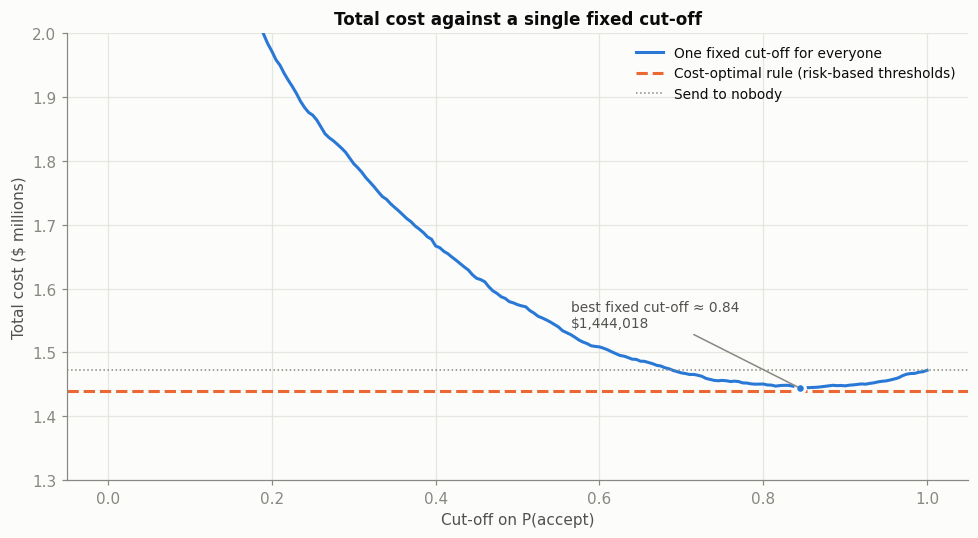

Best single cut-off: 0.84, cost $1,444,018
Cost-optimal rule:   cost $1,439,411


In [26]:
ts = np.linspace(0, 1, 201)
sweep = np.array([realised_cost(q_oof > t, y, p_train).sum() for t in ts])
best_t = ts[sweep.argmin()]
rule_cost = comparison.loc["Cost-optimal rule", "total cost ($)"]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ts, sweep / 1e6, color=SERIES[0], label="One fixed cut-off for everyone")
ax.axhline(rule_cost / 1e6, color=SERIES[1], ls="--", label="Cost-optimal rule (risk-based thresholds)")
ax.axhline(baseline / 1e6, color=MUTED, lw=1, ls=":", label="Send to nobody")
ax.scatter([best_t], [sweep.min() / 1e6], color=SERIES[0], s=40, zorder=3,
           edgecolor=SURFACE, linewidth=2)
ax.annotate(f"best fixed cut-off ≈ {best_t:.2f}\n${sweep.min():,.0f}", (best_t, sweep.min() / 1e6),
            xytext=(-150, 40), textcoords="offset points", fontsize=9, color=INK_2,
            arrowprops=dict(arrowstyle="-", color=MUTED))
ax.set(xlabel="Cut-off on P(accept)", ylabel="Total cost ($ millions)",
       title="Total cost against a single fixed cut-off", ylim=(1.3, 2.0))
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()
print(f"Best single cut-off: {best_t:.2f}, cost ${sweep.min():,.0f}")
print(f"Cost-optimal rule:   cost ${rule_cost:,.0f}")

The risk-based rule beats even the best single cut-off, and that cut-off was picked with hindsight by searching the training labels. The rule needs no such search: its thresholds come straight from the costs and the hospitalisation estimates, so there is nothing to overfit. The chart also shows how badly a cut-off of 0.5, the default for classifiers, does here: it is worse than sending nothing.

### 6.3 Sensitivity analysis

The hospitalisation figures are the least certain input, so the analysis is repeated under other plausible assumptions. *Overlap* is the share of people who get the same decision (send or not) under both the scenario and the base case, among those sent under either.

In [27]:
base_send = q_oof > threshold(p_train)
scenarios = [
    ("Base case", AVG_HOSP_RISK, CHRONIC_RR, VE_HOSP),
    ("Low hospital risk (0.22%)", 0.0022, CHRONIC_RR, VE_HOSP),
    ("High hospital risk (0.94%)", 0.0094, CHRONIC_RR, VE_HOSP),
    ("Vaccine 61% effective", AVG_HOSP_RISK, CHRONIC_RR, 0.61),
    ("Vaccine 72% effective", AVG_HOSP_RISK, CHRONIC_RR, 0.72),
    ("Weaker chronic effect (1/3/5/8)", AVG_HOSP_RISK, {0: 1, 1: 3, 2: 5, 3: 8}, VE_HOSP),
]
rows = []
for name, avg, rr, ve in scenarios:
    p_s = hosp_risk(train, avg=avg, rr=rr)
    send_s = q_oof > threshold(p_s, ve)
    nobody = realised_cost(np.zeros(n, bool), y, p_s, ve).sum()
    rule = realised_cost(send_s, y, p_s, ve).sum()
    half = realised_cost(q_oof >= 0.5, y, p_s, ve).sum()
    rows.append({"scenario": name, "vaccines sent": int(send_s.sum()),
                 "rule cost ($)": rule, "rule saving vs nobody ($)": nobody - rule,
                 "rule saving vs 0.5 cut-off ($)": half - rule,
                 "overlap with base": (send_s & base_send).sum() / max((send_s | base_send).sum(), 1)})
pd.DataFrame(rows).set_index("scenario").style.format({
    "rule cost ($)": "{:,.0f}", "rule saving vs nobody ($)": "{:,.0f}",
    "rule saving vs 0.5 cut-off ($)": "{:,.0f}", "overlap with base": "{:.0%}"})

,vaccines sent,rule cost ($),rule saving vs nobody ($),rule saving vs 0.5 cut-off ($),overlap with base
scenario,,,,,
Base case,457,"1,439,411","32,639","135,458",100%
Low hospital risk (0.22%),273,"1,187,564","11,016","158,394",60%
High hospital risk (0.94%),683,"1,951,563","103,097","110,985",67%
Vaccine 61% effective,513,"1,426,562","45,488","129,127",89%
Vaccine 72% effective,553,"1,413,147","58,903","123,362",83%
Weaker chronic effect (1/3/5/8),489,"1,448,177","23,873","132,096",85%


The rule beats both "send to nobody" and the 0.5 cut-off in every scenario. The exact list of people moves more with the assumed average hospital risk than with vaccine effectiveness or the size of the chronic-condition effect. The people who stay on the list throughout are those with high predicted acceptance *and* chronic conditions.

## 7. Submission

The chosen model is re-fitted on all 4,756 training rows and used to predict acceptance for the test set. The same hospitalisation assumptions and decision rule are then applied. The file follows the example submission exactly: `respondent_id` and `h1n1_vaccine`, with 1.0 meaning *send a vaccine* and 0.0 meaning *don't*.

In [28]:
final_model.fit(X, y)
q_test = final_model.predict_proba(X_test)[:, 1]
p_test = hosp_risk(test)            # scaled with the training population, as above
send_test = q_test > threshold(p_test)

submission = pd.DataFrame({ID_COL: test[ID_COL], TARGET: send_test.astype(float)})
submission.to_csv("submission.csv", index=False)

detail = pd.DataFrame({ID_COL: test[ID_COL], "p_accept": q_test.round(4),
                       "p_hospitalised": p_test.round(5), "threshold": threshold(p_test).round(4),
                       "send_vaccine": send_test.astype(int),
                       "expected_cost": expected_cost(send_test, q_test, p_test).round(2)})
detail.to_csv("test_decisions_detail.csv", index=False)

# Checks against the example file
check = pd.read_csv("submission.csv")
assert list(check.columns) == list(example_sub.columns)
assert list(check[ID_COL]) == list(example_sub[ID_COL])
assert check[TARGET].isin([0.0, 1.0]).all() and check[TARGET].notna().all()
print("submission.csv passes format checks")
print(f"Vaccines to send: {int(send_test.sum()):,} of {len(test):,} ({send_test.mean():.1%})")
print(f"Expected total cost on the test town: ${detail['expected_cost'].sum():,.0f}")
print(f"  for comparison, sending to nobody:  "
      f"${expected_cost(np.zeros(len(test), bool), q_test, p_test).sum():,.0f}")

submission.csv passes format checks
Vaccines to send: 442 of 4,749 (9.3%)
Expected total cost on the test town: $1,425,732
  for comparison, sending to nobody:  $1,458,486


In [29]:
by_group = (detail.assign(chronic=test["number_chronic_med_conditions"].clip(upper=3)
                          .map({0: "0", 1: "1", 2: "2", 3: "3+"}))
            .groupby("chronic").agg(people=("send_vaccine", "size"),
                                    vaccines_sent=("send_vaccine", "sum"),
                                    share_sent=("send_vaccine", "mean")))
by_group.style.format({"share_sent": "{:.1%}"})

,people,vaccines_sent,share_sent
chronic,,,
0,3371,129,3.8%
1,1062,203,19.1%
2,248,76,30.6%
3+,68,34,50.0%


## 8. Conclusions and limitations

**Findings**

* Acceptance can be predicted well (ROC AUC about 0.85). A doctor's recommendation and the person's own beliefs about the vaccine and the disease explain most of it.
* With realistic H1N1 figures, hospitalisation is rare: about 0.45% of infections overall, and around 0.2% for people with no chronic conditions. A vaccine therefore saves little expected hospital cost for most people.
* The cost-optimal policy is selective. It sends vaccines only to people who are very likely to accept, and lowers that bar for people with chronic conditions. On the training data it beats sending to nobody, sending to everyone and the usual 0.5 cut-off.
* The \$500 compensation rule shapes the answer. Someone who will accept costs the town \$500 whether a vaccine is posted or not, so sending to a certain acceptor costs nothing extra and buys protection.

**Limitations**

* Hospitalisation risk comes from published 2009 US estimates, not from this town. The sensitivity analysis shows the policy holds up, but the exact list of people would change if better local figures were available.
* Relative risks for chronic conditions are taken from odds ratios in one case-control study. Odds ratios overstate relative risk somewhat, though the effect is small when the outcome is rare, as it is here.
* Hospitalisation costs are expected values. In a town of about 4,750 people the real number of hospitalisations will vary around the expectation.
* Vaccine effectiveness is treated as the same for everyone. In reality it varies by age and health.
* The survey labels record whether someone *did* get vaccinated in 2009. That stands in for whether they *would* accept a vaccine posted to them, which is not quite the same thing.

### Sources

* CDC (2010). *Updated CDC Estimates of 2009 H1N1 Influenza Cases, Hospitalizations and Deaths in the United States, April 2009 – April 10, 2010.* [Archived PDF](https://webarchive.library.unt.edu/web/20120915211157/http:/www.cdc.gov/h1n1flu/pdf/CDC_2009_H1N1_Est_PDF_May_4_10_fulltext.pdf)
* Ward, K. A., Spokes, P. J. and McAnulty, J. M. (2011). Case–control study of risk factors for hospitalization caused by pandemic (H1N1) 2009. *Emerging Infectious Diseases*, 17(8), 1409. [Table of odds ratios](https://pmc.ncbi.nlm.nih.gov/articles/PMC3381572/table/T1)
* *Effectiveness of nonadjuvanted monovalent influenza A(H1N1)pdm09 vaccines for preventing RT-PCR-confirmed pandemic influenza hospitalizations: case-control study of children and adults at 10 US influenza surveillance network sites.* [eScholarship](https://escholarship.org/uc/item/1xh1f923)
* Lansbury, L. E. et al. (2017). Effectiveness of 2009 pandemic influenza A(H1N1) vaccines: a systematic review and meta-analysis. *Vaccine*. [Repository record](https://nottingham-repository.worktribe.com/output/850652)